# Step 1: Load and inspect raw ETF files

We load the three Kaggle price files (SPY, TLT, XLF), convert the `Date` column to real dates using a strict format so any malformed date stops the notebook, and sort each table by date. We then check for repeated dates and record each file's first date, last date and number of rows. These checks confirm the files cover the expected period (25 Feb 2005 – 10 Nov 2017) before anything is built on them.

In [ ]:
RAW = 'data/raw/' # relative to the notebook's working folder
import os; print(os.listdir(RAW)) # should list the 4 files

['spy.us.txt', 'tlt.us.txt', 'xlf.us.txt', 'VIXCLS.csv']


In [ ]:
import os
import pandas as pd

FILES = {"SPY": "spy.us.txt", "TLT": "tlt.us.txt", "XLF": "xlf.us.txt"}

def load_etf(path):
    df = pd.read_csv(path)

    # strict: raises on bad dates, so pandas stops with an error instead of carrying on.
    df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
    df = df.sort_values("Date", kind="stable").reset_index(drop=True)

    return df

def summarise(ticker, df):
    dup_dates = df.loc[df["Date"].duplicated(keep=False), "Date"].unique()
    return {"ticker": ticker,
            "start": df["Date"].min().date(),
            "end": df["Date"].max().date(),
            "rows": len(df),
            "n_dup_dates": len(dup_dates)}

data = {t: load_etf(os.path.join(RAW, f)) for t, f in FILES.items()}
summary_df = pd.DataFrame([summarise(t, df) for t, df in data.items()]).set_index("ticker")
summary_df

,start,end,rows,n_dup_dates
ticker,,,,
SPY,2005-02-25,2017-11-10,3201,0
TLT,2005-02-25,2017-11-10,3201,0
XLF,2005-02-25,2017-11-10,3201,0


# Step 2: Clean and sanity-check prices

We drop the `OpenInt` column after confirming it is all zeros, since open interest has no meaning for an ETF. We then flag rows that are physically impossible: a High below the Low, a price of zero or less, or negative volume. These rows are reported, not deleted. Genuine extreme days, such as the 2010 flash crash, are kept, because they are exactly the high-volatility events we want to forecast.

In [ ]:
PRICE_COLS = ["Open", "High", "Low", "Close"]

def clean_and_check(ticker, df):
    # 1. OpenInt: confirm it carries no information, then drop it
    assert (df["OpenInt"] == 0).all(), f"[{ticker}] OpenInt has non-zero values"
    df = df.drop(columns="OpenInt")

    # 2. Sanity checks: one boolean mask per rule (True = impossible row)
    checks = {
        "high_below_low": df["High"] < df["Low"],
        "price_not_positive": (df[PRICE_COLS] <= 0).any(axis=1),
        "negative_volume": df["Volume"] < 0,
    }

    # 3. Report, don't delete: print how many rows break each rule
    for rule, mask in checks.items():
        n_bad = int(mask.sum())
        print(f"[{ticker}] {rule}: {n_bad} rows")
        if n_bad:
            print("   dates:", df.loc[mask, "Date"].dt.strftime("%Y-%m-%d").tolist())

    return df

# Apply to the three tables from step 1
data = {t: clean_and_check(t, df) for t, df in data.items()}

[SPY] high_below_low: 0 rows
[SPY] price_not_positive: 0 rows
[SPY] negative_volume: 0 rows
[TLT] high_below_low: 0 rows
[TLT] price_not_positive: 0 rows
[TLT] negative_volume: 0 rows
[XLF] high_below_low: 0 rows
[XLF] price_not_positive: 0 rows
[XLF] negative_volume: 0 rows


# Step 3: Merge VIX and align to SPY trading days

We add the VIX (series VIXCLS from FRED) and combine all four files into one table with one row per SPY trading day. Where TLT, XLF or the VIX has no value for a SPY day, we carry the last known value forward, never backward, so no row ever uses information from the future. A before/after table shows the percentage of missing values in each column.

In [ ]:
# 3a. Load the VIX from FRED; holidays are "." or blank, so read them as missing
vix = pd.read_csv(RAW + "VIXCLS.csv", na_values=".")
vix = vix.rename(columns={vix.columns[0]: "Date", "VIXCLS": "VIX"})  # date column name varies by download
vix["Date"] = pd.to_datetime(vix["Date"], format="%Y-%m-%d")

# 3b. Prefix TLT/XLF columns so they don't clash with SPY's (e.g. "TLT_Close")
def add_prefix(df, ticker):
    return df.rename(columns={c: f"{ticker}_{c}" for c in df.columns if c != "Date"})

tlt = add_prefix(data["TLT"], "TLT")
xlf = add_prefix(data["XLF"], "XLF")

# 3c. Start from SPY's dates and left-join the others onto them
merged = data["SPY"]
for other in [tlt, xlf, vix]:
    merged = merged.merge(other, on="Date", how="left", validate="one_to_one")
assert len(merged) == len(data["SPY"]), "Merge changed the number of SPY rows"

# 3d. % missing per column BEFORE filling
missing_before = merged.isna().mean() * 100

# 3e. Forward-fill only (never backward): copy the last known value onto gaps
fill_cols = [c for c in merged.columns if c.startswith(("TLT_", "XLF_")) or c == "VIX"]
merged[fill_cols] = merged[fill_cols].ffill()

# 3f. % missing AFTER, side by side with before
missing_after = merged.isna().mean() * 100
missing_table = pd.DataFrame({"before_%": missing_before, "after_%": missing_after}).round(2)
missing_table

,before_%,after_%
Date,0.0,0.0
Open,0.0,0.0
High,0.0,0.0
Low,0.0,0.0
Close,0.0,0.0
Volume,0.0,0.0
TLT_Open,0.0,0.0
TLT_High,0.0,0.0
TLT_Low,0.0,0.0
TLT_Close,0.0,0.0


### Step 4: Returns, target and memory features 

We take SPY's daily log returns and use them to measure volatility over the last 1, 5 and 22 trading days (today's move, last week, last month). These are features 1–3, and they are also the inputs of the HAR model. 

The target is the log of volatility over the next 5 trading days.

On 11 days the closing price did not change, so the return is 0 and its log can not be taken. For those days we use the smallest real move from the training years instead. The last line checks that no other day was changed.

In [ ]:
import numpy as np

TRAIN_END = "2014-12-31"   # last training day (plan: train 2005-2014)

def log_returns(close):
    """Daily log return: r_t = ln(Close_t / Close_{t-1}). First row is NaN."""
    return np.log(close).diff()

def log_rv(r, n, floor):
    """Log realised volatility over the n days UP TO AND INCLUDING t (usable as a feature).
    RV = sqrt(sum of squared returns); n=1 gives |r_t|. Values below `floor` are raised to it."""
    rv = np.sqrt(r.pow(2).rolling(n).sum())
    return np.log(rv.clip(lower=floor))

def log_frv(r, n, floor):
    """Log realised volatility over the n days AFTER t (target only, never a feature)."""
    return log_rv(r, n, floor).shift(-n)

# 4a. SPY daily log returns
merged["r"] = log_returns(merged["Close"])

# 4b. Zero-return check: days where the close repeats exactly (prices have only 2-3 decimals)
is_zero  = merged["r"] == 0
is_train = merged["Date"] <= TRAIN_END
print(f"Zero-return days: {is_zero.sum()} (train: {(is_zero & is_train).sum()}, test: {(is_zero & ~is_train).sum()})")
print(merged.loc[is_zero, "Date"].dt.strftime("%Y-%m-%d").tolist())

# 4c. Floor = smallest NON-ZERO |r| in the training period (training only -> no test information).
#     Zero days get the smallest move we can actually measure; no real day is changed.
FLOOR = merged.loc[is_train & ~is_zero, "r"].abs().min()
print(f"Floor: {FLOOR:.2e} (log = {np.log(FLOOR):.2f})")

# 4d. Target: log RV over the next 5 trading days
merged["y"] = log_frv(merged["r"], 5, FLOOR)

# 4e. Features 1-3 (HAR memory): today's move, last week, last month
merged["f1"] = log_rv(merged["r"], 1, FLOOR)    # log RV_1 = log|r_t|
merged["f2"] = log_rv(merged["r"], 5, FLOOR)    # log RV_5
merged["f3"] = log_rv(merged["r"], 22, FLOOR)   # log RV_22

# 4f. Sanity check: the floor changed only the zero-return days
with np.errstate(divide="ignore"):
    changed = (merged["f1"] != np.log(merged["r"].abs())) & merged["r"].notna()
assert changed.sum() == is_zero.sum(), "Floor altered non-zero days"

Zero-return days: 11 (train: 10, test: 1)
['2005-08-22', '2005-11-08', '2007-12-19', '2012-07-30', '2012-10-31', '2013-03-27', '2013-06-10', '2013-07-30', '2013-10-21', '2014-02-26', '2017-01-10']
Floor: 3.27e-05 (log = -10.33)


### Decision check: what to do with zero-return days

On 11 days SPY closed at exactly the same price as the day before, so the return is 0 and log|r| is −∞. Feature 1 can't be computed on those days as it is. We compared three fixes on the training years.

In [ ]:
# Training rows whose 5-day target is also inside the training years (so no 2015 data is used)
in_train = (merged["Date"] <= TRAIN_END) & (merged["Date"].shift(-5) <= TRAIN_END)
r_train = merged.loc[in_train, "r"]

# Three ways to deal with log(0)
options = {
    "drop the zero days": np.log(r_train[r_train != 0].abs()),
    "add 1e-8 to |r|": np.log(r_train.abs() + 1e-8),
    "floor at smallest real move": np.log(r_train.abs().clip(lower=FLOOR)),
}

rows = []
for name, f1 in options.items():
    rows.append({"option": name,
                 "rows kept": len(f1),
                 "lowest value": f1.min(),
                 "values below -12": (f1 < -12).sum(),
                 "corr with target": f1.corr(merged.loc[f1.index, "y"])})
pd.DataFrame(rows).set_index("option").round(3)

,rows kept,lowest value,values below -12,corr with target
option,,,,
drop the zero days,2464,-10.328,0,0.323
add 1e-8 to |r|,2474,-18.421,10,0.277
floor at smallest real move,2474,-10.328,0,0.316


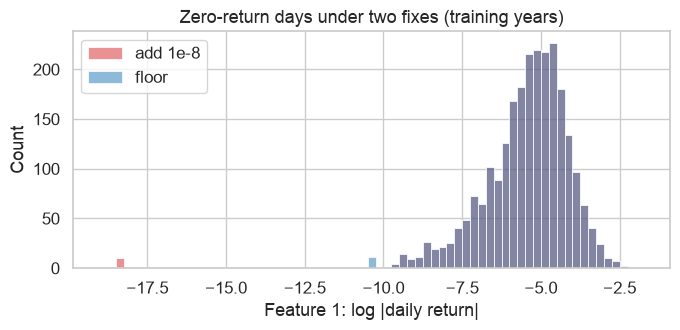

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
os.makedirs("results/figures", exist_ok=True)

bins = np.arange(-19, -1.5, 0.25)   # same bins for both, so the bars are comparable
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(options["add 1e-8 to |r|"], bins=bins, color="tab:red", alpha=0.5, label="add 1e-8", ax=ax)
sns.histplot(options["floor at smallest real move"], bins=bins, color="tab:blue", alpha=0.5, label="floor", ax=ax)
ax.set_xlabel("Feature 1: log |daily return|")
ax.set_title("Zero-return days under two fixes (training years)")
ax.legend()
plt.tight_layout()
plt.show()

**Result.** Adding 1e-8 pushes the 10 zero-return days in the training years down to −18.4, far below every real day (the smallest real move gives −10.3), and it weakens the link with the target (correlation 0.28 instead of 0.32). Dropping the days keeps the correlation (0.32) but throws away 10 days of data. The floor keeps every row, creates no outliers and keeps almost the same correlation (0.32), so we use the floor.

# Step 5 — Build the leverage feature (5)

We add SPY's 1-day log return with its sign kept (f5 = rₜ). Feature 1 already measures the size of today's move; this feature adds its direction, because falls tend to raise future volatility more than rises of the same size (the leverage effect). It uses only day t's return, so it is known at time t and leaks nothing from the future. A quick check on the training period confirms the effect in our data: after the 10% biggest falls, next-week log volatility averages −3.44, against −3.70 after the 10% biggest rises and −4.03 overall.

In [ ]:
# 5a. Feature 5 (leverage effect): today's return WITH its sign.
#     f1 already holds the SIZE of today's move (log|r_t|); f5 adds its DIRECTION.
merged["f5"] = merged["r"]

# 5b. Sanity check: f5 uses only day t's return (no shift), so it is known at t -> no leakage
assert merged["f5"].equals(merged["r"]), "f5 must equal today's return"

# 5c. Leverage-effect check, on TRAINING data only (the test set stays untouched until Sat 14 Nov):
#     average next-week log volatility after the biggest falls vs the biggest rises
train = merged[merged["Date"] <= TRAIN_END]
low, high = train["f5"].quantile([0.10, 0.90])
print(f"Mean y after the 10% biggest falls: {train.loc[train['f5'] <= low,  'y'].mean():.2f}")
print(f"Mean y after the 10% biggest rises: {train.loc[train['f5'] >= high, 'y'].mean():.2f}")
print(f"Mean y on all training days:        {train['y'].mean():.2f}")

Mean y after the 10% biggest falls: -3.44
Mean y after the 10% biggest rises: -3.70
Mean y on all training days:        -4.03


# Step 6 — Build VIX and cross-asset features (4, 6–8)

Feature 4 is the log of the VIX. Features 6 and 7 reuse the volatility function from step 4 on the bond ETF (TLT) and the bank ETF (XLF). Feature 7 is a difference of two logs, which is the log of a ratio: how many times more volatile banks are than the whole market. Feature 8 is the bond ETF's return over the last 22 trading days. All four only use data up to day t.

In [ ]:
# Feature 4: log of the VIX
merged["f4"] = np.log(merged["VIX"])

# Daily log returns of the bond ETF (TLT) and the bank ETF (XLF)
merged["TLT_r"] = log_returns(merged["TLT_Close"])
merged["XLF_r"] = log_returns(merged["XLF_Close"])

# Feature 6: bond volatility over the last 22 days
merged["f6"] = log_rv(merged["TLT_r"], 22, FLOOR)

# Feature 7: bank volatility minus market volatility = log(XLF RV / SPY RV)
merged["f7"] = log_rv(merged["XLF_r"], 22, FLOOR) - merged["f3"]

# Feature 8: bond return over the last 22 days
merged["f8"] = np.log(merged["TLT_Close"] / merged["TLT_Close"].shift(22))

merged[["f4", "f6", "f7", "f8"]].describe().round(3)

,f4,f6,f7,f8
count,3201.000,3179.000,3179.000,3179.000
mean,2.855,-3.310,0.364,0.004
std,0.387,0.356,0.255,0.039
min,2.213,-4.475,-0.236,-0.153
25%,2.561,-3.559,0.187,-0.020
50%,2.773,-3.352,0.314,0.003
75%,3.084,-3.061,0.517,0.026
max,4.393,-2.232,1.332,0.245


# Step 7 — Build activity and trend features (9–10)

Feature 9 compares today's trading volume with the average of the last 22 days, today included. It is close to 0 on a normal day and positive on a busy one. Feature 10 is SPY's return over the last 22 trading days, the market's trend over the past month.

In [ ]:
# Feature 9: today's volume compared with the average of the last 22 days (0 = a normal day)
merged["f9"] = np.log(merged["Volume"] / merged["Volume"].rolling(22).mean())

# Feature 10: SPY return over the last 22 days
merged["f10"] = np.log(merged["Close"] / merged["Close"].shift(22))

merged[["f9", "f10"]].describe().round(3)

,f9,f10
count,3180.000,3179.000
mean,-0.045,0.006
std,0.326,0.046
min,-1.746,-0.364
25%,-0.250,-0.012
50%,-0.055,0.013
75%,0.150,0.032
max,1.321,0.195


### Decision check: should the volume average include today?

We know today's volume at the close, so including it is not leakage. We still checked whether leaving it out makes a difference, on the training years.

In [ ]:
volume = merged["Volume"]
with_today = np.log(volume / volume.rolling(22).mean())
without_today = np.log(volume / volume.shift(1).rolling(22).mean())

y_train = merged.loc[in_train, "y"]
print("Correlation with next week's volatility (training years):")
print(f"  average includes today: {with_today[in_train].corr(y_train):.3f}")
print(f"  average excludes today: {without_today[in_train].corr(y_train):.3f}")
print(f"Correlation between the two versions: {with_today[in_train].corr(without_today[in_train]):.3f}")

Correlation with next week's volatility (training years):
  average includes today: 0.157
  average excludes today: 0.163
Correlation between the two versions: 0.999


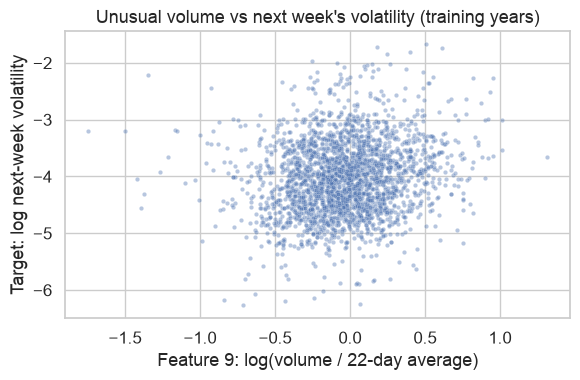

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(x=merged.loc[in_train, "f9"], y=y_train, s=10, alpha=0.4, ax=ax)
ax.set_xlabel("Feature 9: log(volume / 22-day average)")
ax.set_ylabel("Target: log next-week volatility")
ax.set_title("Unusual volume vs next week's volatility (training years)")
plt.tight_layout()
plt.savefig("results/figures/volume_vs_target.png", dpi=200)
plt.show()

**Result.** The two versions are almost the same series (correlation 0.999), and their link with next week's volatility is about the same: 0.157 with today included, 0.163 without. The difference is too small to matter, so we keep the definition from the plan (today included). The scatter plot also shows that volume on its own is a weak signal. The models will tell us whether it adds anything on top of past volatility.

# Step 8 — Trim incomplete rows, split and save model table

The first 22 days have no full 22-day window and the last 5 days have no target yet, so we drop them. We then split by date: training up to 31 Dec 2014, test from 1 Jan 2015. Finally we apply the embargo: the last 5 training rows are removed, because their targets use returns from early January 2015, which belong to the test period. The saved table only contains `train` and `test` rows.

In [ ]:
FEATURES = ["f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8", "f9", "f10"]

# Drop rows where the target or a feature can't be computed:
# the first 22 days (no full 22-day window) and the last 5 days (no next-5-day target)
table = merged.dropna(subset=["y"] + FEATURES)
print("Rows dropped:", len(merged) - len(table))

# Split by date
train = table[table["Date"] <= TRAIN_END]
test = table[table["Date"] > TRAIN_END]

# Embargo: the last 5 training rows have targets that reach into January 2015 (test period)
embargo = train.tail(5)
print("Embargoed rows, and the last day each one's target uses:")
for i in embargo.index:
    print("  ", embargo.loc[i, "Date"].date(), "->", merged.loc[i + 5, "Date"].date())
train = train.iloc[:-5]

Rows dropped: 27
Embargoed rows, and the last day each one's target uses:
   2014-12-24 -> 2015-01-02
   2014-12-26 -> 2015-01-05
   2014-12-29 -> 2015-01-06
   2014-12-30 -> 2015-01-07
   2014-12-31 -> 2015-01-08


In [ ]:
# Save one table with a split column. Every model loads only this file.
train = train.assign(split="train")
test = test.assign(split="test")
model_table = pd.concat([train, test])[["Date", "y"] + FEATURES + ["split"]]
model_table = model_table.rename(columns={"Date": "date"})

os.makedirs("data/processed", exist_ok=True)
model_table.to_csv("data/processed/model_table.csv", index=False)

print(f"Train: {len(train)} rows, {train['Date'].min().date()} to {train['Date'].max().date()}")
print(f"Test:  {len(test)} rows, {test['Date'].min().date()} to {test['Date'].max().date()}")

Train: 2452 rows, 2005-03-30 to 2014-12-23
Test:  717 rows, 2015-01-02 to 2017-11-03


# Step 9 — Set up CV splitter, metrics and prediction export

Every model tunes with the same time-series cross-validation: `TimeSeriesSplit(n_splits=5, gap=5)` on the training rows only. Each fold fits on the earlier years and scores on the next block, so a model never trains on the future. Two shared functions live in `src/foundation/evaluate.py`: `evaluate()` returns MAE, RMSE and R², and `save_predictions()` writes a model's test forecasts to `results/preds_<model>.csv`. The test set is not used anywhere in this notebook.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from src.foundation.evaluate import evaluate, save_predictions   # run the notebook from the repo root

# Every model loads the saved table like this
model_table = pd.read_csv("data/processed/model_table.csv", parse_dates=["date"])
train = model_table[model_table["split"] == "train"].reset_index(drop=True)
test = model_table[model_table["split"] == "test"].reset_index(drop=True)

# 5 folds inside the training years, with a 5-row gap between fitting and scoring
tscv = TimeSeriesSplit(n_splits=5, gap=5)
for k, (fit_idx, val_idx) in enumerate(tscv.split(train), start=1):
    print(f"Fold {k}: fit {train['date'][fit_idx[0]].date()} to {train['date'][fit_idx[-1]].date()}, "
          f"score {train['date'][val_idx[0]].date()} to {train['date'][val_idx[-1]].date()}")

Fold 1: fit 2005-03-30 to 2006-11-06, score 2006-11-14 to 2008-06-30
Fold 2: fit 2005-03-30 to 2008-06-23, score 2008-07-01 to 2010-02-11
Fold 3: fit 2005-03-30 to 2010-02-04, score 2010-02-12 to 2011-09-26
Fold 4: fit 2005-03-30 to 2011-09-19, score 2011-09-27 to 2013-05-13
Fold 5: fit 2005-03-30 to 2013-05-06, score 2013-05-14 to 2014-12-23


### Decision check: why a gap of 5 rows?

Each target looks 5 trading days ahead. Without a gap, the last fitted row's target would be built from the same days that are being scored.

In [ ]:
for gap in [0, 5]:
    fit_idx, val_idx = next(iter(TimeSeriesSplit(n_splits=5, gap=gap).split(train)))
    last_fit = fit_idx[-1]
    print(f"gap={gap}: last fitted row {train['date'][last_fit].date()} "
          f"(its target uses days up to {train['date'][last_fit + 5].date()}), "
          f"first scored row {train['date'][val_idx[0]].date()}")

gap=0: last fitted row 2006-11-13 (its target uses days up to 2006-11-20), first scored row 2006-11-14
gap=5: last fitted row 2006-11-06 (its target uses days up to 2006-11-13), first scored row 2006-11-14


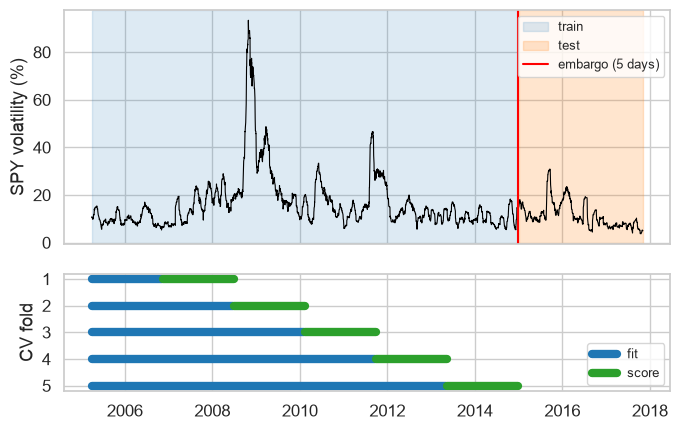

In [ ]:
# Figure: train / embargo / test over time, and the 5 CV folds
spy_vol = np.exp(model_table["f3"]) * np.sqrt(252 / 22) * 100   # last month's volatility, annualised %

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 4.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(model_table["date"], spy_vol, color="black", lw=0.8)
ax1.axvspan(train["date"].min(), train["date"].max(), color="tab:blue", alpha=0.15, label="train")
ax1.axvspan(test["date"].min(), test["date"].max(), color="tab:orange", alpha=0.2, label="test")
ax1.axvline(train["date"].max(), color="red", lw=1.5, label="embargo (5 days)")
ax1.set_ylabel("SPY volatility (%)")
ax1.legend(loc="upper right", fontsize=9)

for k, (fit_idx, val_idx) in enumerate(tscv.split(train), start=1):
    ax2.plot([train["date"][fit_idx[0]], train["date"][fit_idx[-1]]], [k, k], color="tab:blue", lw=6,
             label="fit" if k == 1 else None)
    ax2.plot([train["date"][val_idx[0]], train["date"][val_idx[-1]]], [k, k], color="tab:green", lw=6,
             label="score" if k == 1 else None)
ax2.set_yticks(range(1, 6))
ax2.set_ylabel("CV fold")
ax2.invert_yaxis()
ax2.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig("results/figures/split_cv_timeline.png", dpi=200)
plt.show()

### First CV score: the naive forecast

Before any model, we score the simplest forecast (next week's volatility = last week's, feature 2) on each fold. This also checks that `evaluate()` works.

In [ ]:
scores = [evaluate(train["y"][val_idx], train["f2"][val_idx]) for _, val_idx in tscv.split(train)]
pd.DataFrame(scores, index=range(1, 6)).rename_axis("fold").round(3)

,MAE,RMSE,R2
fold,,,
1,0.464,0.621,-0.229
2,0.367,0.480,0.432
3,0.433,0.569,0.130
4,0.467,0.607,-0.179
5,0.444,0.552,-0.284


**Result.** The naive forecast works best in fold 2, which covers the 2008 crisis (R² 0.43). In folds 1, 4 and 5 its R² is below zero, so it does worse than simply predicting the average. Last week's volatility on its own is too noisy, which is why HAR also uses the last day and the last month.

## What we tried

| Problem | What we tried | What happened | What we chose |
|---|---|---|---|
| log(0) on the 11 days with a zero return | Drop the days / add 1e-8 / floor at the smallest real move | 1e-8 gave 10 outliers at −18.4 and a weaker link with the target (0.28 vs 0.32); dropping lost 10 days of data | Floor |
| Volume average with or without today | Both versions, on the training years | Almost identical (0.999); correlation with the target 0.157 vs 0.163 | Keep today, as planned |
| Naive forecast as a baseline | Scored on the 5 CV folds | R² between −0.28 and 0.43, below zero in 3 of 5 folds | Use HAR as the benchmark |
| LightGBM overfits with default settings | Compared RMSE on the fitted years with the next block | 0.13 vs 0.58 | Small grid search; chosen settings give 0.36 vs 0.53 |
| Best LightGBM settings at the edge of the grid | Tried smaller values (3 leaves, learning rate 0.005, 100 trees) | Same settings still best (CV RMSE 0.529) | Keep 7 leaves, 0.01, 200 trees |
| LightGBM fails in the 2008 crisis fold (R² −0.56) | `linear_tree=True`, so it can forecast beyond the training range | Worse: RMSE 0.609, fold 2 R² −2.9 | Keep ordinary trees; report it as a limitation |
| Best Elastic Net `l1_ratio` at the edge of the grid (1.0, i.e., the Lasso) | Compared every `l1_ratio` at the best `alpha` (0.01); 1.0 is the upper limit, so the grid cannot be extended | CV RMSE 0.437 for both 1.0 and 0.9, 0.439 for 0.5, 0.443 for 0.1: pure L1 and the mixed penalties are practically tied | Keep `alpha` 0.01 and `l1_ratio` 1.0; report the tie |

Each member adds a row here when something in their model doesn't work, with the real numbers.